> **Web-runner version** of the Colab participant notebook. `data_dir` and `out_dir` are parameters set by the server; the last cell exports map layers for the viewer. Everything else is the original teaching material.

# Module 4 – Spatial Regression and Bayesian Disease Mapping
**Participant notebook (R in Google Colab)**

This notebook contains every code cell of the training manual, in the same order and with the same step numbers, so you can run it alongside the manual. Run the cells from top to bottom; each topic depends on objects created earlier.

Before starting: **Runtime → Change runtime type → Language: R**. Then run the setup cells. When a session resets, run the setup cells again and continue where you were.

Text cells give the step; the manual has the explanations, the expected outputs and the figures, so compare your output with the manual after each cell.

# Introduction to Module 4

## Setting up: Google Colab and R

The routine is the one from the earlier modules. Only the file names and the package list change.

In [ ]:
# Parameters: the web app (papermill) overrides these for every run.
data_dir    <- "/data/module4_data"
out_dir     <- "/srv/jobs/outputs"

In [ ]:
project_dir <- file.path(out_dir, "project")      # Module 2 builds its project folder here
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)
# a data zip with one extra top-level folder: step into it
.sub <- list.dirs(data_dir, recursive = FALSE); .fil <- list.files(data_dir)
if (length(.sub) == 1 && length(.fil) == 0) data_dir <- .sub
cat("Data directory:", data_dir, "\n")
list.files(data_dir, recursive = TRUE)

Packages. MASS provides glm.nb() for the negative-binomial regression; broom's tidy() turns a model into a table of rate ratios; mgcv fits the hierarchical spatial model (it is part of every R installation); spdep is the Module 1 package for neighbours; patchwork and scales help with figures. Nothing in this module needs a package that is not on CRAN.

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
suppressPackageStartupMessages({
  library(tidyverse); library(sf); library(spdep); library(MASS); library(broom); library(mgcv)
  library(scales); library(patchwork)
})
select <- dplyr::select        # MASS also has a select(); make sure dplyr's wins
options(width = 95)
dir.create(out_dir, showWarnings = FALSE)

### Loading the model inputs

In [ ]:
# Module 2B prepared the district table this module models: observed and expected cases, SIR, covariates
inputs_path    <- list.files(data_dir, pattern = "^district_year_2024\\.rds$", recursive = TRUE, full.names = TRUE)[1]
districts_path <- list.files(data_dir, pattern = "^ghana_districts\\.gpkg$", recursive = TRUE, full.names = TRUE)[1]
if (is.na(inputs_path)) stop("district_year_2024.rds not found: run Module 2B on the Module 2 panel and use its outputs as the dataset")

ann       <- read_rds(inputs_path)
districts <- st_read(districts_path, quiet = TRUE)
rate <- sum(ann$O) / sum(ann$population * ann$months / 12)   # the national reference rate behind E
nrow(ann); round(rate * 1000, 1)                              # districts; national cases per 1,000 person-years

# Topic 1 – Outcome, Exposure and the Standardised Incidence Ratio

## 1.4 Step by step in R with Ama's data

Steps 1 and 2 — one row per district for 2024, then the national rate, expected cases and the SIR — are in **Module 2B**, and the table loaded above is their result: `O`, `E`, `SIR`, `months` and the covariates for every district. This module starts from that table.

In [ ]:
districts |> left_join(ann |> select(adm2_code, SIR), by = "adm2_code") |> ggplot() +
  geom_sf(aes(fill = SIR), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("SIR", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1, limits = c(0, 2.6)) +
  labs(title = "Standardised incidence ratio, 2024", subtitle = "observed / expected at the national rate; 1 = national average") + theme_minimal()

### VISUAL 3 · Poisson variation, uncertainty and overdispersion

<div style="width:100%; margin:18px 0 22px; text-align:center;">
  <img src="attachment:poisson_uncertainty_infographic.png" alt="VISUAL 3 · Poisson variation, uncertainty and overdispersion"        width="1448" style="width:100%; max-width:1448px; height:auto; display:block; margin:auto;" />
</div>

*Illustrative learning diagram — verify real calculations with the notebook code and outputs.*

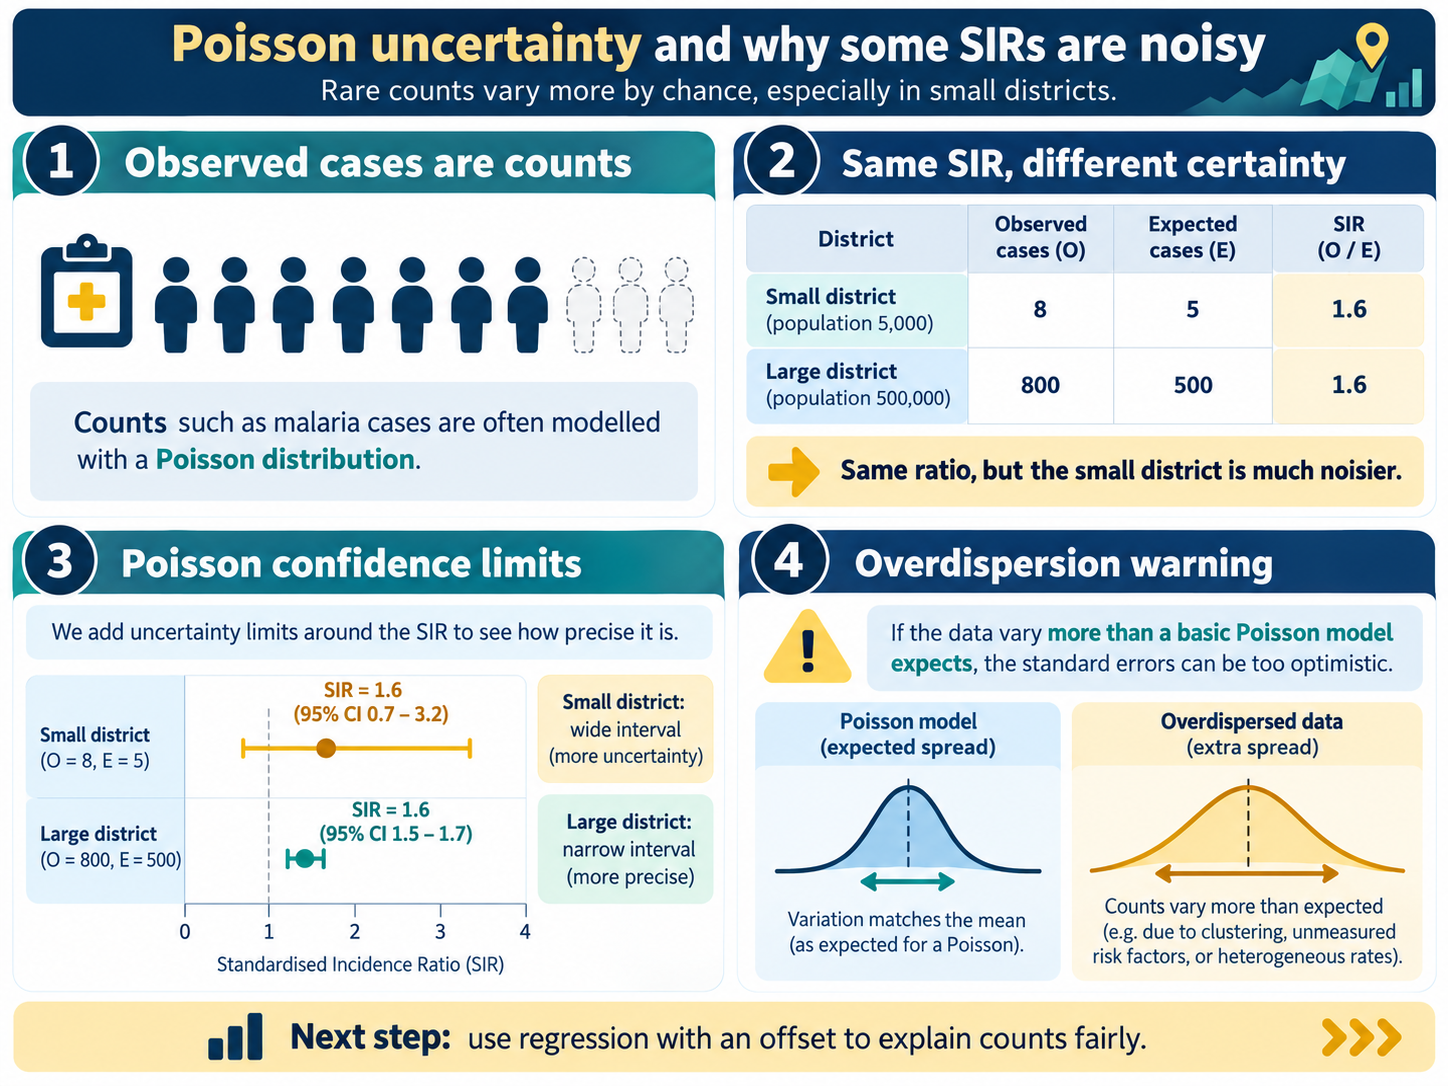

Step 3. How far can an SIR move by chance? The Poisson limits, and how many districts fall outside them.

In [ ]:
# how far can an SIR wander by chance alone? Poisson limits around 1 shrink as E grows
ann <- ann |> mutate(lo95 = 1 - 1.96 / sqrt(E), hi95 = 1 + 1.96 / sqrt(E), outside = SIR < lo95 | SIR > hi95)
ann |> summarise(districts = n(), outside_95 = sum(outside), share = round(mean(outside), 2))
ann |> mutate(size = cut(E, c(0, 5000, 20000, Inf), labels = c("E < 5,000", "5,000-20,000", "E > 20,000"))) |>
  group_by(size) |> summarise(n = n(), sd_SIR = round(sd(SIR), 2), min = round(min(SIR), 2), max = round(max(SIR), 2))

247 of 260 districts (95 percent) lie outside the Poisson limits, and the spread of SIRs is about the same for small and large districts (standard deviations 0.39, 0.47 and 0.33). If chance were the only source of variation, the small districts would scatter far more than the large ones and only 5 percent would be outside. The counts are heavily over-dispersed.

In [ ]:
funnel <- tibble(E = seq(min(ann$E), max(ann$E), length.out = 200)) |> mutate(lo = 1 - 1.96 / sqrt(E), hi = 1 + 1.96 / sqrt(E))
ggplot(ann, aes(E, SIR)) + geom_hline(yintercept = 1, colour = "grey50") +
  geom_line(data = funnel, aes(y = lo), colour = "#C9A063", linewidth = 1) + geom_line(data = funnel, aes(y = hi), colour = "#C9A063", linewidth = 1) +
  geom_point(aes(colour = eco_zone), alpha = 0.8) + scale_x_log10(labels = comma) +
  labs(title = "Funnel plot: SIR against expected cases", subtitle = "gold lines: 95% Poisson limits if every district had the national rate\nalmost every district lies outside them: the variation is far more than chance",
       x = "expected cases E (log scale)", y = "SIR", colour = NULL) + theme_minimal() + theme(legend.position = "bottom")

## 1.8 Trial test 1

Answer the trial test on paper (manual section 1.8). Answers are at the end of the manual.

# Topic 2 – Regression for Spatial Count Data

## 2.4 Step by step in R with Ama's data

### VISUAL 4 · Poisson regression and the population offset

<div style="width:100%; margin:18px 0 22px; text-align:center;">
  <img src="attachment:poisson_regression_offset_infographic.png" alt="VISUAL 4 · Poisson regression and the population offset"        width="1448" style="width:100%; max-width:1448px; height:auto; display:block; margin:auto;" />
</div>

*Illustrative learning diagram — verify real calculations with the notebook code and outputs.*

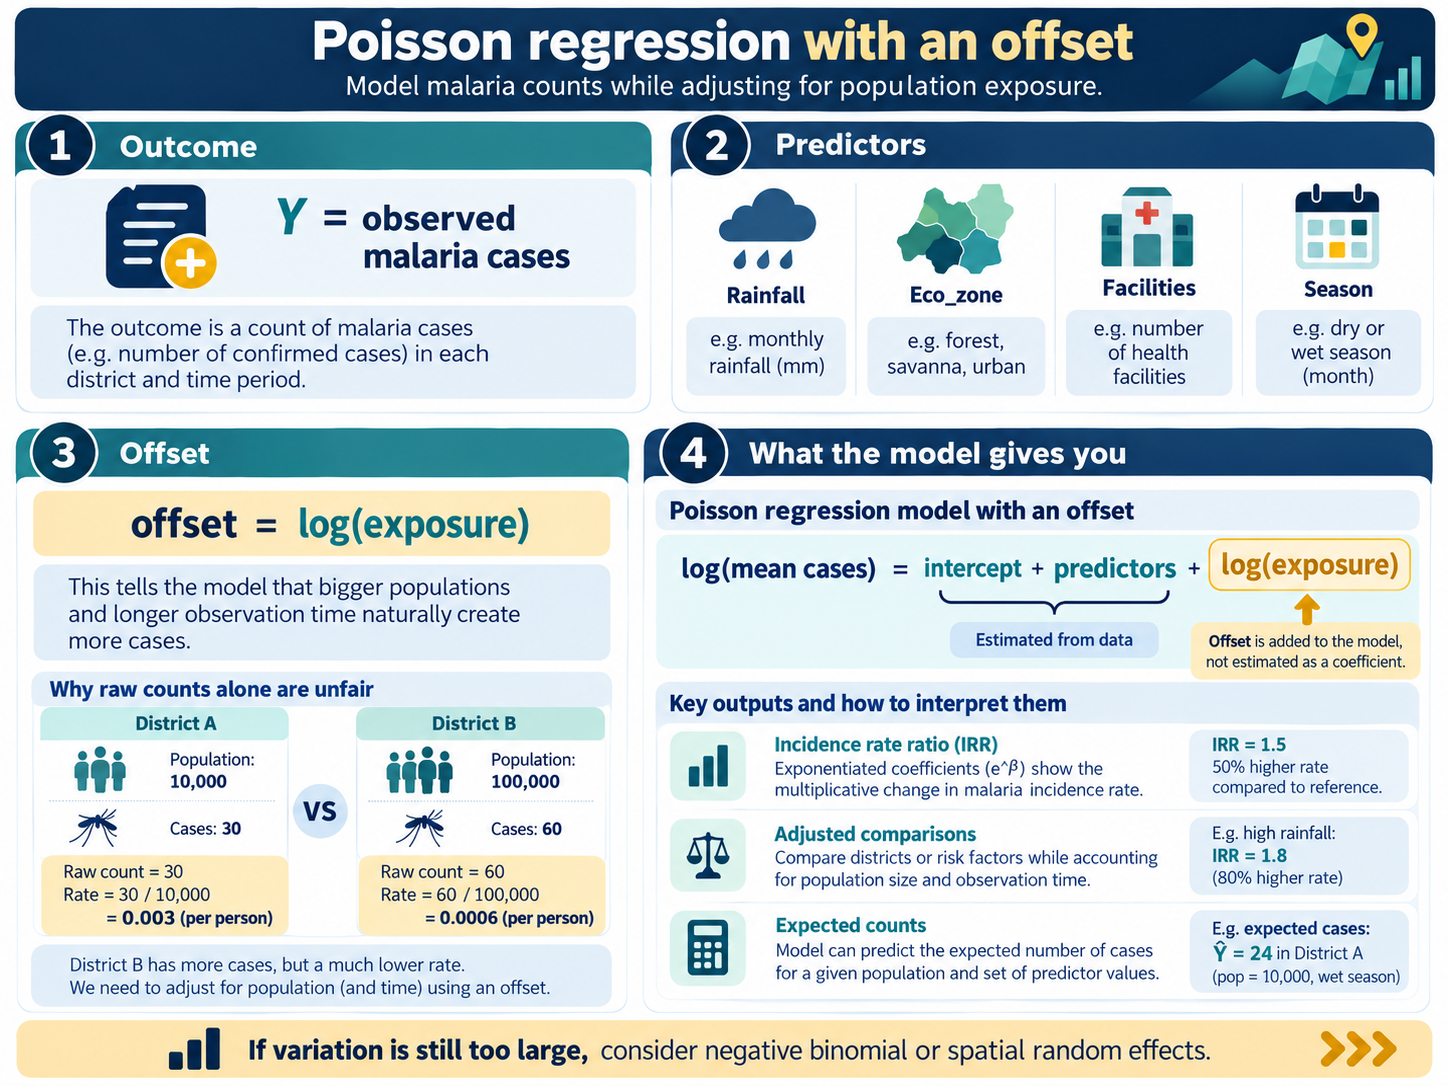

Step 1. The Poisson model with an offset, its rate ratios, and the dispersion check.

In [ ]:
fit_p <- glm(O ~ rain100 + tmean + ndvi10 + elev100 + logdens + fac + offset(log(E)), family = poisson, data = ann)
tidy(fit_p, exponentiate = TRUE, conf.int = TRUE) |> mutate(across(where(is.numeric), ~ round(.x, 3)))
dispersion <- sum(residuals(fit_p, type = "pearson")^2) / df.residual(fit_p)
round(dispersion, 1)                                           # 1 = Poisson holds; here it is far above 1

Every predictor is 'highly significant' and the dispersion is 1,506. The second number cancels the first: the Poisson variance is wrong by three orders of magnitude, so the standard errors are meaningless.

Step 2. The negative-binomial model.

In [ ]:
fit_nb <- glm.nb(O ~ rain100 + tmean + ndvi10 + elev100 + logdens + fac + offset(log(E)), data = ann)
tidy(fit_nb, exponentiate = TRUE, conf.int = TRUE) |> mutate(across(where(is.numeric), ~ round(.x, 3)))
round(fit_nb$theta, 2)                                         # NB dispersion parameter; small = very over-dispersed
AIC(fit_p, fit_nb)

Same rate ratios, honest intervals: rainfall 0.73 (0.45 to 1.17), facilities 1.17 (0.94 to 1.47), and every interval includes 1. Theta is 5.7, and the AIC drops from 399,251 to 4,991. Nothing about the negative-binomial fit is better at predicting the counts; it is better at saying how little it knows.

In [ ]:
tidy(fit_nb, exponentiate = TRUE, conf.int = TRUE) |> filter(term != "(Intercept)") |>
  ggplot(aes(estimate, term)) + geom_vline(xintercept = 1, colour = "grey50") +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2, colour = "#010066") + geom_point(colour = "#010066", size = 2.5) +
  scale_x_log10() + labs(title = "Negative-binomial model: rate ratios with 95% confidence intervals", subtitle = "units: 100 mm monthly rain, 1 degree C, 0.1 NDVI, 100 m elevation, log density, 1 facility per 10,000",
                         x = "rate ratio (log scale)", y = NULL) + theme_minimal()

Step 3. What the model reproduces, and what it leaves in the residuals.

In [ ]:
# is there spatial structure the covariates did not explain? (Module 1 weights, Module 3 test)
nb_q <- poly2nb(districts, queen = TRUE); names(nb_q) <- districts$adm2_code
lw_q <- nb2listw(nb_q, style = "W", zero.policy = TRUE)
ann  <- ann |> arrange(match(adm2_code, districts$adm2_code))   # same row order as the polygons
ann$res_nb <- residuals(fit_nb, type = "pearson")
moran.test(ann$res_nb, lw_q, zero.policy = TRUE)$estimate[1] |> round(3)
moran.mc(ann$res_nb, lw_q, nsim = 999, zero.policy = TRUE)$p.value
ann$fit_nb <- fitted(fit_nb)
ann |> summarise(r_obs_fit = round(cor(O, fit_nb), 3), mae = round(mean(abs(O - fit_nb)), 0))

The residuals have Moran's I of 0.138 with a Monte Carlo p-value of 0.001: districts with positive residuals sit next to districts with positive residuals. The fitted values correlate 0.92 with the observed counts, but that is mostly the offset doing its work; the mean absolute error is about 3,500 cases per district.

In [ ]:
districts |> left_join(ann |> select(adm2_code, res_nb), by = "adm2_code") |> ggplot() +
  geom_sf(aes(fill = res_nb), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("Pearson\nresidual", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0, limits = c(-3, 3), oob = squish) +
  labs(title = "Residuals of the negative-binomial model", subtitle = "red: more cases than the covariates predict\nthe north is red together: structure the covariates missed") + theme_minimal()

## 2.8 Trial test 2

Answer the trial test on paper (manual section 2.8). Answers are at the end of the manual.

# Topic 3 – Bayesian Hierarchical Spatial Models: Borrowing Strength

## 3.4 Step by step in R with Ama's data

### VISUAL 5 · Bayesian spatial disease mapping

<div style="width:100%; margin:18px 0 22px; text-align:center;">
  <img src="attachment:bayesian_spatial_disease_mapping_infographic.png" alt="VISUAL 5 · Bayesian spatial disease mapping"        width="1448" style="width:100%; max-width:1448px; height:auto; display:block; margin:auto;" />
</div>

*Illustrative learning diagram — verify real calculations with the notebook code and outputs.*

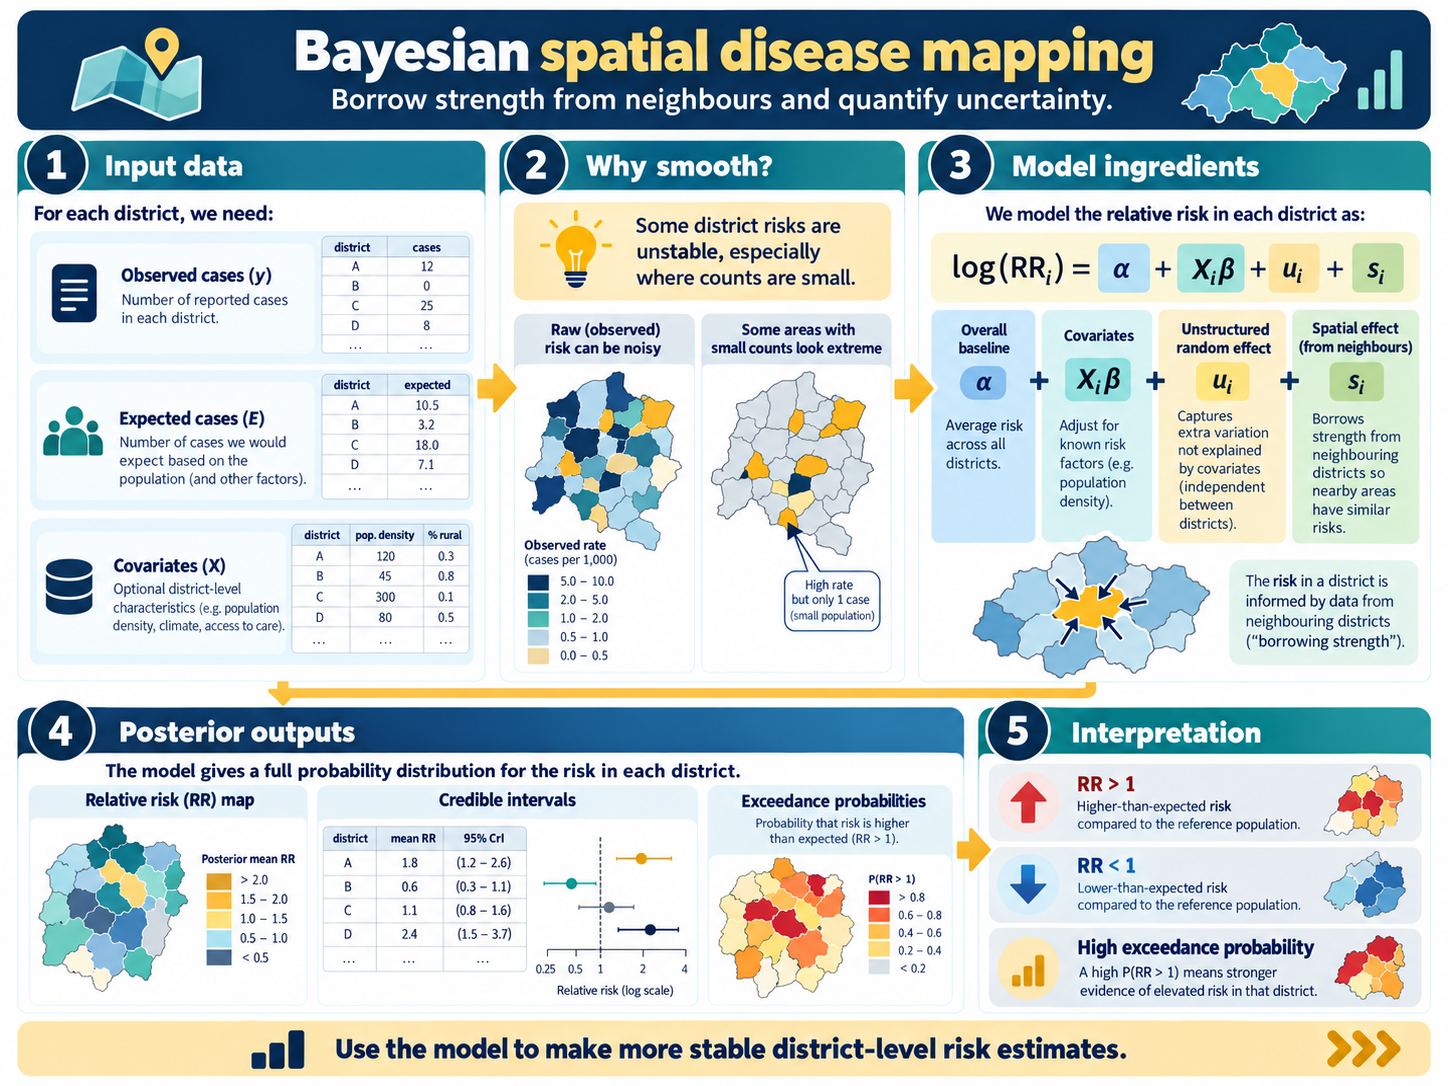

Step 1. The spatial model without covariates. The neighbour list from Topic 2 becomes the structure of the Markov random field; the response is the count with the offset, and the family is negative binomial.

In [ ]:
# the district effect gets an ICAR prior: each district effect is expected to be near the mean of its neighbours
ann$id <- factor(ann$adm2_code, levels = districts$adm2_code)
m_sp <- gam(O ~ s(id, bs = "mrf", xt = list(nb = nb_q)) + offset(log(E)),
            family = nb(), data = ann, method = "REML")
summary(m_sp)$s.table
round(m_sp$family$getTheta(TRUE), 2)

The spatial term is strongly supported (chi-squared 120 on 34 effective degrees of freedom); theta is 6.9, so district-only variation remains substantial after the spatial structure is accounted for.

Step 2. Posterior relative risks. The model matrix without the offset, 1,000 draws of the coefficients from their posterior, and the relative risk under each draw.

In [ ]:
# posterior relative risk per district: draw 1,000 coefficient vectors from the posterior and push them through the model
Xp   <- predict(m_sp, type = "lpmatrix")                     # rows = districts, columns = model terms (offset excluded)
beta <- rmvn(1000, coef(m_sp), vcov(m_sp))                  # 1,000 posterior draws of the coefficients
RR   <- exp(Xp %*% t(beta))                                  # 260 x 1000 matrix of relative-risk draws
ann  <- ann |> mutate(RR_mean = rowMeans(RR), RR_lo = apply(RR, 1, quantile, 0.025), RR_hi = apply(RR, 1, quantile, 0.975))
ann |> select(adm2_name, O, E, SIR, RR_mean, RR_lo, RR_hi) |> mutate(across(c(E, SIR, RR_mean, RR_lo, RR_hi), ~ round(.x, 2))) |> head(6)

Each district now has a posterior mean RR and a credible interval. Tano North, SIR 1.47, has posterior RR 0.89 (0.69 to 1.12): its own count was high, its neighbours were not, and with E of about 8,000 under this much over-dispersion the neighbours won. Asutifi North, SIR 0.60, is pulled up to 0.84.

Step 3. Who moved and how far.

In [ ]:
# shrinkage: the smallest districts move most, the largest hardly at all
ann |> mutate(shift = RR_mean - SIR) |> arrange(E) |> select(adm2_name, E, SIR, RR_mean, shift) |> mutate(across(c(E, SIR, RR_mean, shift), ~ round(.x, 2))) |> head(5)
ann |> mutate(shift = RR_mean - SIR) |> arrange(-E) |> select(adm2_name, E, SIR, RR_mean, shift) |> mutate(across(c(E, SIR, RR_mean, shift), ~ round(.x, 2))) |> head(3)
ann |> summarise(sd_SIR = round(sd(SIR), 3), sd_RR = round(sd(RR_mean), 3), cor = round(cor(SIR, RR_mean), 3))

The five smallest districts move by 0.1 to 0.65; the three largest by 0.06 to 0.45. Even Bole, with E of 65,000, moves from 0.50 to 0.95, which says how little the model trusts a single district's count under this level of over-dispersion (theta near 7 means a standard deviation of about 38 percent of the mean, whatever E is). The spread of risk across districts halves (0.44 to 0.25) and the correlation between SIR and posterior RR is 0.78.

In [ ]:
ggplot(ann, aes(SIR, RR_mean)) + geom_abline(colour = "grey60") + geom_hline(yintercept = 1, colour = "grey85") +
  geom_point(aes(size = E, colour = eco_zone), alpha = 0.7) + scale_size_area(max_size = 6, labels = comma) +
  labs(title = "Shrinkage: crude SIR against posterior relative risk", subtitle = "on the diagonal: unchanged; small circles (small E) move furthest toward their neighbours",
       x = "SIR (observed / expected)", y = "posterior mean RR", colour = NULL, size = "expected cases") + theme_minimal()

In [ ]:
mp <- districts |> left_join(ann |> select(adm2_code, SIR, RR_mean), by = "adm2_code")
a <- ggplot(mp) + geom_sf(aes(fill = SIR), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("ratio", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1, limits = c(0, 2.6)) + labs(title = "Crude SIR") + theme_minimal()
b <- ggplot(mp) + geom_sf(aes(fill = RR_mean), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("ratio", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1, limits = c(0, 2.6)) + labs(title = "Posterior mean RR (spatial model)") + theme_minimal()
a + b + plot_layout(guides = "collect")

### The same model in R-INLA (for reference; Module 5 runs it)

R-INLA fits the full BYM2 model, with an explicit structured and unstructured effect and a mixing parameter phi that says what share of the variation is spatial. The code below is the INLA equivalent of Step 1 and Step 2 and is not run in this module; it needs the INLA package installed from its own repository, which Module 5 sets up. The results agree closely with the mgcv fit.

**For reference only (not run in Module 4 — Module 5 installs INLA):** the same model in R-INLA.

```r
# install.packages("INLA", repos = c(getOption("repos"), INLA = "https://inla.r-inla-download.org/R/stable"))
library(INLA)
nb2INLA("/content/ghana.adj", nb_q); g <- inla.read.graph("/content/ghana.adj")
ann$idx <- as.integer(ann$id)
res <- inla(O ~ 1 + f(idx, model = "bym2", graph = g,
                      hyper = list(prec = list(prior = "pc.prec", param = c(1, 0.01)),
                                   phi  = list(prior = "pc",      param = c(0.5, 0.5)))),
            family = "nbinomial", data = ann, E = E,
            control.compute = list(dic = TRUE, waic = TRUE, cpo = TRUE),
            control.predictor = list(compute = TRUE))
summary(res)                                   # fixed effects, hyperparameters (precision, phi), DIC / WAIC
ann$RR_inla <- res$summary.fitted.values$mean  # posterior mean RR; quantiles in the same table
```

## 3.8 Trial test 3

Answer the trial test on paper (manual section 3.8). Answers are at the end of the manual.

# Topic 4 – Covariates, Model Comparison and What the Spatial Term Means

## 4.4 Step by step in R with Ama's data

Step 1. The spatial model with the six covariates of Topic 2, and a helper that turns any model into a rate-ratio table.

In [ ]:
m_cov <- gam(O ~ rain100 + tmean + ndvi10 + elev100 + logdens + fac + s(id, bs = "mrf", xt = list(nb = nb_q)) + offset(log(E)),
             family = nb(), data = ann, method = "REML")
rr_tab <- function(m) { ci <- confint.default(m); tibble(term = names(coef(m)), RR = exp(coef(m)), lo = exp(ci[, 1]), hi = exp(ci[, 2])) |>
  filter(!str_detect(term, "s\\(id\\)"), term != "(Intercept)") |> mutate(across(c(RR, lo, hi), ~ round(.x, 3))) }
rr_tab(m_cov)
summary(m_cov)$s.table

The rate ratios are close to those of the plain negative binomial (rainfall 0.72, facilities 1.13) with intervals that still include 1, and the spatial term is still needed (edf 29, p = 0.003). The covariates have not explained the pattern.

In [ ]:
bind_rows(tidy(fit_nb, exponentiate = TRUE, conf.int = TRUE) |> filter(term != "(Intercept)") |> transmute(model = "NB GLM (Topic 2)", term, RR = estimate, lo = conf.low, hi = conf.high),
          rr_tab(m_cov) |> mutate(model = "spatial + covariates")) |>
  ggplot(aes(RR, term, colour = model)) + geom_vline(xintercept = 1, colour = "grey50") +
  geom_errorbarh(aes(xmin = lo, xmax = hi), height = 0.2, position = position_dodge(width = 0.5)) + geom_point(position = position_dodge(width = 0.5), size = 2.5) +
  scale_x_log10() + scale_colour_manual(values = c("#C9A063", "#010066")) +
  labs(title = "Rate ratios with and without the spatial term", x = "rate ratio (log scale)", y = NULL, colour = NULL) + theme_minimal() + theme(legend.position = "bottom")

Step 2. The ecological zone as a covariate.

In [ ]:
# the ecological zone as a covariate: what the spatial term was standing in for
ann <- ann |> mutate(eco_zone = factor(eco_zone, levels = c("Forest", "Coastal savannah", "Transition", "Guinea savannah")))
m_eco <- gam(O ~ eco_zone + elev100 + logdens + fac + s(id, bs = "mrf", xt = list(nb = nb_q)) + offset(log(E)),
             family = nb(), data = ann, method = "REML")
rr_tab(m_eco)
summary(m_eco)$s.table

Relative to the forest zone, the Guinea savannah has 1.65 times the rate (1.34 to 2.03); the coastal savannah and transition zones are indistinguishable from the forest. And the spatial term has collapsed: edf 6.8, p = 0.16. Once the zone is in the model there is almost no spatially structured variation left to smooth.

Step 3. The comparison table, and the plain regression with the zone.

In [ ]:
# how much of the spatial pattern is left in the spatial term, model by model
sp_effect <- function(m) predict(m, type = "terms")[, "s(id)"]
tibble(model = c("spatial only", "spatial + climate covariates", "spatial + eco-zone"),
       edf_spatial = round(c(summary(m_sp)$s.table[1], summary(m_cov)$s.table[1], summary(m_eco)$s.table[1]), 1),
       sd_spatial  = round(c(sd(sp_effect(m_sp)), sd(sp_effect(m_cov)), sd(sp_effect(m_eco))), 3),
       AIC         = round(c(AIC(m_sp), AIC(m_cov), AIC(m_eco)), 1))
fit_eco_glm <- glm.nb(O ~ eco_zone + elev100 + logdens + fac + offset(log(E)), data = ann)
round(AIC(fit_nb), 1); round(AIC(fit_eco_glm), 1)
moran.test(residuals(fit_eco_glm, type = "pearson"), lw_q, zero.policy = TRUE)$estimate[1] |> round(3)

The standard deviation of the fitted spatial effect falls from 0.22 (spatial only) to 0.15 with the climate covariates and to 0.03 with the zone. In the plain negative-binomial regression the zone improves AIC from 4,991 to 4,965 and the residual Moran's I from 0.138 to 0.002. The ecological zone is the geography.

In [ ]:
sp <- districts |> left_join(tibble(adm2_code = ann$adm2_code, before = sp_effect(m_sp), after = sp_effect(m_eco)), by = "adm2_code")
a <- ggplot(sp) + geom_sf(aes(fill = exp(before)), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("spatial\neffect", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1, limits = c(0.5, 2.2)) + labs(title = "Spatial effect, no covariates") + theme_minimal()
b <- ggplot(sp) + geom_sf(aes(fill = exp(after)), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("spatial\neffect", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1, limits = c(0.5, 2.2)) + labs(title = "Spatial effect after ecological zone") + theme_minimal()
a + b + plot_layout(guides = "collect")

## 4.8 Trial test 4

Answer the trial test on paper (manual section 4.8). Answers are at the end of the manual.

# Topic 5 – Uncertainty, Exceedance Probabilities and Communicating Risk

## 5.4 Step by step in R with Ama's data

### VISUAL 6 · Posterior exceedance probabilities

<div style="width:100%; margin:18px 0 22px; text-align:center;">
  <img src="attachment:exceedance_probability_district_guide.png" alt="VISUAL 6 · Posterior exceedance probabilities"        width="1448" style="width:100%; max-width:1448px; height:auto; display:block; margin:auto;" />
</div>

*Illustrative learning diagram — verify real calculations with the notebook code and outputs.*

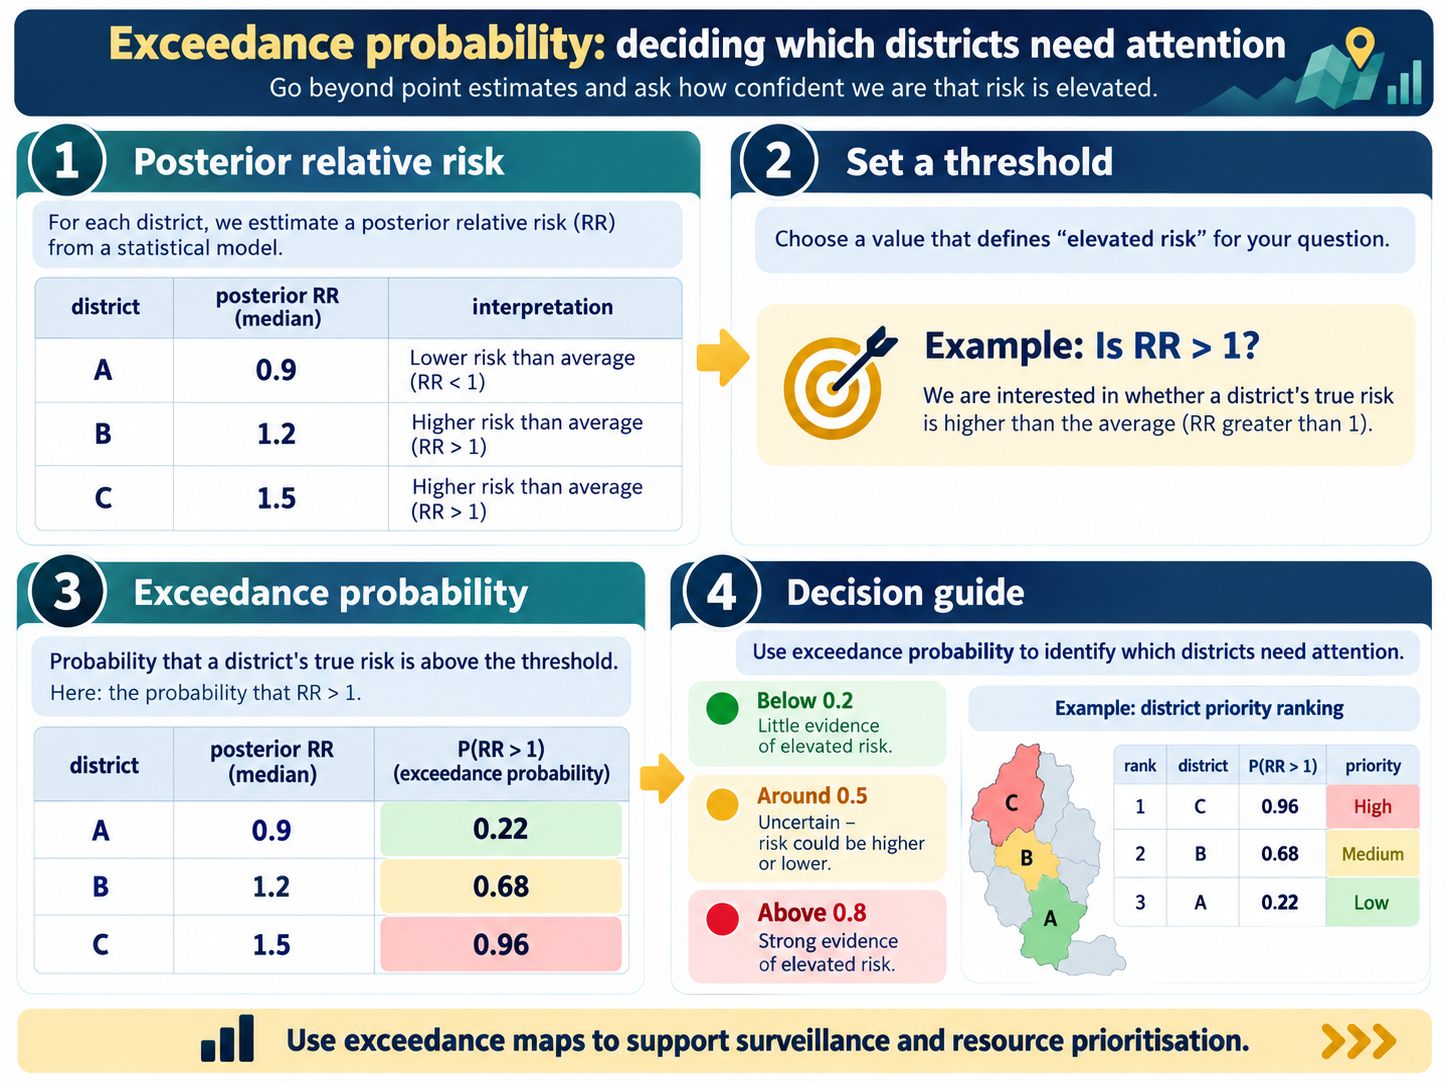

Step 1. Exceedance probabilities and interval widths from the posterior draws.

In [ ]:
# exceedance probabilities from the posterior draws of the disease-mapping model
ann <- ann |> mutate(p_gt1  = rowMeans(RR > 1),
                     p_gt15 = rowMeans(RR > 1.5),
                     ci_width = RR_hi - RR_lo)
ann |> summarise(above_0.8 = sum(p_gt1 > 0.8), above_0.95 = sum(p_gt1 > 0.95), p15_above_0.8 = sum(p_gt15 > 0.8))
ann |> arrange(-p_gt15) |> select(adm2_name, region, O, RR_mean, RR_lo, RR_hi, p_gt1, p_gt15) |>
  mutate(across(c(RR_mean, RR_lo, RR_hi, p_gt1, p_gt15), ~ round(.x, 2))) |> head(8)

Nabdam has posterior RR 1.87 (1.34 to 2.51), P(RR > 1) of 1.00 and P(RR > 1.5) of 0.90. Bolgatanga Municipal, eighth, has P(RR > 1.5) of 0.78 and would be just outside a rule set at 0.8; the rule decides, so the rule is reported.

In [ ]:
mp <- districts |> left_join(ann |> select(adm2_code, RR_mean, ci_width, p_gt15), by = "adm2_code")
a <- ggplot(mp) + geom_sf(aes(fill = RR_mean), colour = "white", linewidth = 0.1) + scale_fill_gradient2("RR", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1) + labs(title = "Posterior mean RR") + theme_void()
b <- ggplot(mp) + geom_sf(aes(fill = ci_width), colour = "white", linewidth = 0.1) + scale_fill_viridis_c("width", option = "mako", direction = -1) + labs(title = "Width of the 95% credible interval") + theme_void()
c <- ggplot(mp) + geom_sf(aes(fill = p_gt15), colour = "white", linewidth = 0.1) + scale_fill_viridis_c("P(RR > 1.5)", option = "inferno", direction = -1, limits = c(0, 1)) + labs(title = "Probability that RR exceeds 1.5") + theme_void()
a + b + c

Step 2. Risk and certainty together.

In [ ]:
# risk and certainty together: two dimensions, four messages
ann <- ann |> mutate(risk = if_else(RR_mean > 1.2, "high", "not high"),
                     certain = if_else(p_gt1 > 0.9 | p_gt1 < 0.1, "certain", "uncertain"),
                     class = case_when(risk == "high" & certain == "certain" ~ "High risk, certain: act",
                                       risk == "high" ~ "High risk, uncertain: investigate",
                                       certain == "certain" ~ "Not high, certain: routine",
                                       TRUE ~ "Not high, uncertain: watch"))
ann |> count(class)
ann |> filter(class == "High risk, uncertain: investigate") |> select(adm2_name, region, E, RR_mean, RR_lo, RR_hi, p_gt1) |>
  mutate(across(c(E, RR_mean, RR_lo, RR_hi, p_gt1), ~ round(.x, 2))) |> head(6)

Thirty-eight districts are high risk and certain; two (Saboba, Nandom) are high risk but uncertain; and 132 are 'not high but uncertain', which is the honest size of the group about which the 2024 data say little. Saboba's interval runs from 0.91 to 1.56: probably elevated, not certainly.

In [ ]:
districts |> left_join(ann |> select(adm2_code, class), by = "adm2_code") |> ggplot() + geom_sf(aes(fill = class), colour = "white", linewidth = 0.1) +
  scale_fill_manual(values = c("High risk, certain: act" = "#B2182B", "High risk, uncertain: investigate" = "#F4A582", "Not high, certain: routine" = "#D1E5F0", "Not high, uncertain: watch" = "#92C5DE"), name = NULL) +
  labs(title = "Risk and certainty together", subtitle = "high risk: posterior mean RR > 1.2\ncertain: P(RR > 1) above 0.9 or below 0.1") +
  theme_minimal() + theme(legend.position = "bottom") + guides(fill = guide_legend(nrow = 2))

Step 3. The priority table and the district layer, written to files for the directorate and for QGIS.

In [ ]:
priority <- ann |> filter(p_gt15 > 0.8) |> arrange(-RR_mean) |>
  select(adm2_name, region, population, O, RR_mean, RR_lo, RR_hi, p_gt15, class)
nrow(priority)
priority |> mutate(across(c(RR_mean, RR_lo, RR_hi, p_gt15), ~ round(.x, 2))) |> print(n = 20)
write_csv(priority, file.path(out_dir, "priority_districts_2024.csv"))
st_write(districts |> select(adm2_code) |> left_join(ann |> select(adm2_code, O, E, SIR, RR_mean, RR_lo, RR_hi, p_gt1, p_gt15, class), by = "adm2_code"),
         file.path(out_dir, "malaria_rr_2024.gpkg"), delete_dsn = TRUE, quiet = TRUE)
list.files(out_dir)

Seven districts meet the rule P(RR > 1.5) > 0.8, all in the Upper East, together holding about 400,000 people. The GeoPackage carries every district's O, E, SIR, posterior RR, interval, exceedance probabilities and class, so that a colleague can redraw any map without R.

### Step 4. The modelling report

The report is a page. Ama's, built from the checkpoint numbers of this module, follows this section. Its structure is fixed: data and exposure; the crude picture and its limits; the regression and what it did not explain; the spatial model and the shrinkage; the covariates and what the spatial term stood for; the posterior outputs, thresholds and rule; the priority list; the caveats.

## 5.8 Trial test 5

Answer the trial test on paper (manual section 5.8). Answers are at the end of the manual.

---
End of the module. Download anything you want to keep from the Files panel before the session ends.

## Export for the web map viewer

Added by `tools/prepare_notebooks.py`: writes the map layers listed in `layers.json`.

In [ ]:
# ---- Export for the web map viewer (added by tools/prepare_notebooks.py) ----
# Each block below is wrapped in safe(): if a step was edited or skipped, the other layers are
# still written. The viewer discovers everything through layers.json.
layers <- list()
safe <- function(label, expr) tryCatch(expr, error = function(e)
  message("Export skipped - ", label, ": ", conditionMessage(e)))
add_layer <- function(...) layers[[length(layers) + 1]] <<- list(...)
wgs <- function(x) sf::st_transform(x, 4326)

# district polygons, in lon/lat, lightly simplified for the web
web_districts <- function(d, tol = 0.002) {
  d <- wgs(d)
  keep <- intersect(c("adm2_code", "adm2_name", "region", "eco_zone"), names(d))
  suppressWarnings(sf::st_simplify(d[, keep], preserveTopology = TRUE, dTolerance = tol))
}
write_geojson <- function(x, name) {
  f <- file.path(out_dir, paste0(name, ".geojson"))
  if (file.exists(f)) file.remove(f)
  x <- dplyr::mutate(x, dplyr::across(dplyr::where(is.numeric), ~ round(.x, 4)))
  sf::st_write(x, f, driver = "GeoJSON", quiet = TRUE, layer_options = "COORDINATE_PRECISION=5")
}
# long district-month table -> one column per month (inc_2024_01, ...) + field list for the slider
widen_months <- function(df, value, prefix) {
  df <- as.data.frame(df)
  d  <- data.frame(adm2_code = df$adm2_code, key = paste0(prefix, "_", format(df$month, "%Y_%m")), v = df[[value]])
  m  <- sort(unique(df$month))
  list(wide   = tidyr::pivot_wider(d, names_from = "key", values_from = "v"),
       fields = lapply(m, function(x) list(field = paste0(prefix, "_", format(x, "%Y_%m")), label = format(x, "%b %Y"))))
}
# x/y/value data frame -> heat-point JSON for the browser + a GeoTIFF for GIS users
heat_export <- function(df, name, crs = 32630, max_pts = 25000) {
  df <- df[is.finite(df$value), c("x", "y", "value")]
  tryCatch(terra::writeRaster(terra::rast(df, type = "xyz", crs = paste0("EPSG:", crs)),
                              file.path(out_dir, paste0(name, ".tif")), overwrite = TRUE),
           error = function(e) message("GeoTIFF skipped for ", name, ": ", conditionMessage(e)))
  if (nrow(df) > max_pts) df <- df[round(seq(1, nrow(df), length.out = max_pts)), ]
  ll <- sf::st_coordinates(wgs(sf::st_as_sf(df, coords = c("x", "y"), crs = crs)))
  jsonlite::write_json(list(points = data.frame(lat = ll[, 2], lng = ll[, 1], value = df$value)),
                       file.path(out_dir, paste0(name, ".heat.json")), digits = 6)
}
im_df  <- function(im) { d <- as.data.frame(im); names(d)[3] <- "value"; d }          # spatstat image
pts_df <- function(s, col) { xy <- sf::st_coordinates(s); data.frame(x = xy[, 1], y = xy[, 2], value = s[[col]]) }

# Disease mapping: SIR, posterior relative risk, uncertainty, exceedance probability, risk classes
safe("disease map", {
  rr_cols <- list("High risk, certain: act" = "#B2182B", "High risk, uncertain: investigate" = "#F4A582",
                  "Not high, certain: routine" = "#D1E5F0", "Not high, uncertain: watch" = "#92C5DE")
  a <- ann |> dplyr::select(dplyr::any_of(c("adm2_code", "O", "E", "SIR", "RR_mean", "RR_lo", "RR_hi", "ci_width",
                                            "p_gt1", "p_gt15", "class", "res_nb", "eco_zone")))
  extra <- NULL
  if (exists("sp") && inherits(sp, "sf")) extra <- sf::st_drop_geometry(sp) |>
    dplyr::transmute(adm2_code, spatial_effect_before = exp(before), spatial_effect_after = exp(after))
  d <- web_districts(districts) |> dplyr::select(-dplyr::any_of("eco_zone")) |> dplyr::left_join(a, by = "adm2_code")
  if (!is.null(extra)) d <- dplyr::left_join(d, extra, by = "adm2_code")
  write_geojson(d, "disease_map")
  add_layer(id = "dm", title = "Bayesian disease map, 2024", kind = "choropleth", file = "disease_map.geojson",
    source = "malaria_rr_2024.gpkg",
    fields = list(
      list(field = "RR_mean",  label = "Posterior mean relative risk", type = "numeric"),
      list(field = "SIR",      label = "Crude SIR (observed / expected)", type = "numeric"),
      list(field = "class",    label = "Risk and certainty", type = "category", colors = rr_cols),
      list(field = "p_gt15",   label = "Probability that RR exceeds 1.5", type = "numeric"),
      list(field = "p_gt1",    label = "Probability that RR exceeds 1", type = "numeric"),
      list(field = "ci_width", label = "Width of the 95% credible interval", type = "numeric"),
      list(field = "res_nb",   label = "Negative-binomial Pearson residual", type = "numeric"),
      list(field = "spatial_effect_before", label = "Spatial effect, no covariates", type = "numeric"),
      list(field = "spatial_effect_after",  label = "Spatial effect after eco-zone", type = "numeric"))) })

jsonlite::write_json(list(layers = layers), file.path(out_dir, "layers.json"),
                     auto_unbox = TRUE, null = "null", na = "null")
cat("Exported", length(layers), "map layer(s) to", out_dir, "\n")
print(list.files(out_dir))
